# Klasifikasi Multilabel - Dokumentasi 3 Dataset

**Definisi:** satu data dapat memiliki **lebih dari satu label sekaligus**. Target berupa matriks biner `n_data x n_label`.

| No | Dataset | Sumber |
|---|---|---|
| 1 | Jigsaw Toxic Comment Classification | Kaggle competition (Jigsaw/Conversation AI) |
| 2 | Indonesian Multi-label Hate Speech & Abusive Language | GitHub, Ibrohim & Budi (2019) |
| 3 | GoEmotions | Google Research (via Hugging Face) |

Ukuran penting:
- **Label Cardinality**: rata-rata jumlah label aktif per data.
- **Label Density**: cardinality dibagi jumlah label.
- **% Data >1 Label**: persentase data yang benar-benar multilabel.

In [1]:
%pip install -q datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, io, os
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 160)

def muat_csv(nama_file, **kw):
    """Baca CSV lokal; jika tidak ada dan berjalan di Colab, minta upload file."""
    if os.path.exists(nama_file):
        return pd.read_csv(nama_file, **kw)
    try:
        from google.colab import files
        print(f"Upload file: {nama_file}")
        up = files.upload()
        return pd.read_csv(io.BytesIO(next(iter(up.values()))), **kw)
    except ImportError:
        raise FileNotFoundError(f"Letakkan {nama_file} di folder yang sama dengan notebook ini.")

def analisis_single_label(nama, y, nama_kelas=None):
    y = pd.Series(np.asarray(y).ravel()).reset_index(drop=True)
    vc = y.value_counts().sort_index()
    if nama_kelas is not None:
        vc.index = [nama_kelas.get(i, i) for i in vc.index]
    persen = (vc / vc.sum() * 100).round(2)
    tabel = pd.DataFrame({"Jumlah": vc, "Persentase (%)": persen})
    rin = {"Dataset": nama, "Jumlah Data": int(vc.sum()), "Jumlah Kelas": int(len(vc)),
           "Kelas Mayoritas (%)": float(persen.max()), "Kelas Minoritas (%)": float(persen.min()),
           "Imbalance Ratio": round(vc.max() / vc.min(), 2),
           "Tipe Terdeteksi": "Biner" if len(vc) == 2 else ("Multikelas" if len(vc) > 2 else "Satu kelas")}
    return tabel, rin

def analisis_multilabel(nama, Y, nama_label):
    Y = np.asarray(Y).astype(int); n, L = Y.shape; pb = Y.sum(axis=1); card = pb.mean()
    tabel = pd.DataFrame({"Jumlah": Y.sum(axis=0), "Persentase (%)": (Y.mean(axis=0) * 100).round(2)}, index=list(nama_label))
    rin = {"Dataset": nama, "Jumlah Data": n, "Jumlah Label": L,
           "Label Cardinality": round(card, 3), "Label Density": round(card / L, 3),
           "% Data 0 Label": round((pb == 0).mean() * 100, 2), "% Data 1 Label": round((pb == 1).mean() * 100, 2),
           "% Data >1 Label (Multilabel)": round((pb > 1).mean() * 100, 2), "Maks Label per Data": int(pb.max()),
           "Tipe Terdeteksi": "Multilabel" if (pb > 1).any() else "Bukan multilabel"}
    return tabel, rin

def plot_bar(ax, tabel, judul, horizontal=False):
    s = tabel["Persentase (%)"]
    (s.plot(kind="barh", ax=ax, color="steelblue") if horizontal else s.plot(kind="bar", ax=ax, color="steelblue"))
    ax.set_title(judul); (ax.set_xlabel if horizontal else ax.set_ylabel)("Persentase (%)")

## 1. Jigsaw Toxic Comment Classification
- **Sumber:** https://www.kaggle.com/c/jigsaw-toxic-comment-classification-challenge/data (perlu login Kaggle dan menyetujui aturan kompetisi)
- **Pembuat:** Jigsaw / Conversation AI (2017-2018)
- **Deskripsi:** komentar Wikipedia yang dilabeli rater manusia untuk perilaku toksik
- **Jumlah data (train):** 159.571 komentar
- **Label (6):** `toxic`, `severe_toxic`, `obscene`, `threat`, `insult`, `identity_hate`
- **File yang diunggah:** `train.csv` (jika berupa zip, ekstrak dulu)

In [3]:
df_jig = muat_csv("train.csv")
lab_jig = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]
print(df_jig.shape); display(df_jig.head(3))
tab_jig, rin_jig = analisis_multilabel("Jigsaw Toxic", df_jig[lab_jig].values, lab_jig)
display(tab_jig)

(159571, 8)


,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0


,Jumlah,Persentase (%)
toxic,15294,9.58
severe_toxic,1595,1.00
obscene,8449,5.29
threat,478,0.30
insult,7877,4.94
identity_hate,1405,0.88


## 2. Indonesian Multi-label Hate Speech and Abusive Language
- **Sumber:** https://github.com/okkyibrohim/id-multi-label-hate-speech-and-abusive-language-detection
- **Pembuat:** Muhammad Okky Ibrohim & Indra Budi (2019), ALW3, hlm. 46-57. https://aclanthology.org/W19-3506/
- **Deskripsi:** tweet berbahasa Indonesia untuk deteksi ujaran kebencian dan bahasa kasar, termasuk target, kategori, dan tingkat
- **Jumlah data:** 13.169 tweet
- **Label (12):** HS, Abusive, HS_Individual, HS_Group, HS_Religion, HS_Race, HS_Physical, HS_Gender, HS_Other, HS_Weak, HS_Moderate, HS_Strong
- **Lisensi:** CC BY-NC-SA 4.0 (nonkomersial). Dimuat otomatis dari GitHub.

In [4]:
url_id = ("https://raw.githubusercontent.com/okkyibrohim/"
          "id-multi-label-hate-speech-and-abusive-language-detection/master/re_dataset.csv")
df_id = pd.read_csv(url_id, encoding="ISO-8859-1")
lab_id = ["HS", "Abusive", "HS_Individual", "HS_Group", "HS_Religion", "HS_Race",
          "HS_Physical", "HS_Gender", "HS_Other", "HS_Weak", "HS_Moderate", "HS_Strong"]
print(df_id.shape); display(df_id.head(3))
tab_id, rin_id = analisis_multilabel("Indonesian HS", df_id[lab_id].values, lab_id)
display(tab_id)

(13169, 13)


,Tweet,HS,Abusive,HS_Individual,HS_Group,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,HS_Weak,HS_Moderate,HS_Strong
0,- disaat semua cowok berusaha melacak perhatia...,1,1,1,0,0,0,0,0,1,1,0,0
1,RT USER: USER siapa yang telat ngasih tau elu?...,0,1,0,0,0,0,0,0,0,0,0,0
2,"41. Kadang aku berfikir, kenapa aku tetap perc...",0,0,0,0,0,0,0,0,0,0,0,0


,Jumlah,Persentase (%)
HS,5561,42.23
Abusive,5043,38.29
HS_Individual,3575,27.15
HS_Group,1986,15.08
HS_Religion,793,6.02
HS_Race,566,4.30
HS_Physical,323,2.45
HS_Gender,306,2.32
HS_Other,3740,28.40
HS_Weak,3383,25.69


## 3. GoEmotions
- **Sumber:** https://github.com/google-research/google-research/tree/master/goemotions (dimuat dari Hugging Face: `google-research-datasets/go_emotions`)
- **Pembuat:** Demszky dkk. (2020), ACL. Google Research, Stanford, Amazon Alexa. Lisensi Apache 2.0.
- **Deskripsi:** komentar Reddit berbahasa Inggris dengan satu atau lebih label dari 27 emosi atau Neutral
- **Jumlah data:** versi `simplified` terdiri dari 43.410 latih, 5.426 validasi, 5.427 uji
- **Label (28):** 27 emosi + `neutral`

In [5]:
from datasets import load_dataset
from sklearn.preprocessing import MultiLabelBinarizer

go = load_dataset("google-research-datasets/go_emotions", "simplified")
nama_go = go["train"].features["labels"].feature.names
semua = [l for split in ("train", "validation", "test") for l in go[split]["labels"]]
Y_go = MultiLabelBinarizer(classes=list(range(len(nama_go)))).fit_transform(semua)
print("Jumlah data:", Y_go.shape[0], "| Jumlah label:", Y_go.shape[1])
tab_go, rin_go = analisis_multilabel("GoEmotions", Y_go, nama_go)
display(tab_go.sort_values("Persentase (%)", ascending=False))

README.md:   0%|          | 0.00/9.40k [00:00<?, ?B/s]

simplified/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.77MB            

simplified/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

simplified/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B /  350kB            

simplified/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

simplified/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  347kB            

... (2 outputs left out)

Generating validation split:   0%|          | 0/5426 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5427 [00:00<?, ? examples/s]

Jumlah data: 54263 | Jumlah label: 28


,Jumlah,Persentase (%)
neutral,17772,32.75
admiration,5122,9.44
approval,3687,6.79
gratitude,3372,6.21
annoyance,3093,5.70
amusement,2895,5.34
curiosity,2723,5.02
disapproval,2581,4.76
love,2576,4.75
optimism,1976,3.64


## Perbandingan 3 Dataset Multilabel

Dataset,Jigsaw Toxic,Indonesian HS,GoEmotions
Jumlah Data,159571,13169,54263
Jumlah Label,6,12,28
Label Cardinality,0.22,2.085,1.176
Label Density,0.037,0.174,0.042
% Data 0 Label,89.83,44.5,0.0
% Data 1 Label,3.99,13.27,83.75
% Data >1 Label (Multilabel),6.18,42.23,16.25
Maks Label per Data,6,7,5
Tipe Terdeteksi,Multilabel,Multilabel,Multilabel
Valid Multilabel?,True,True,True


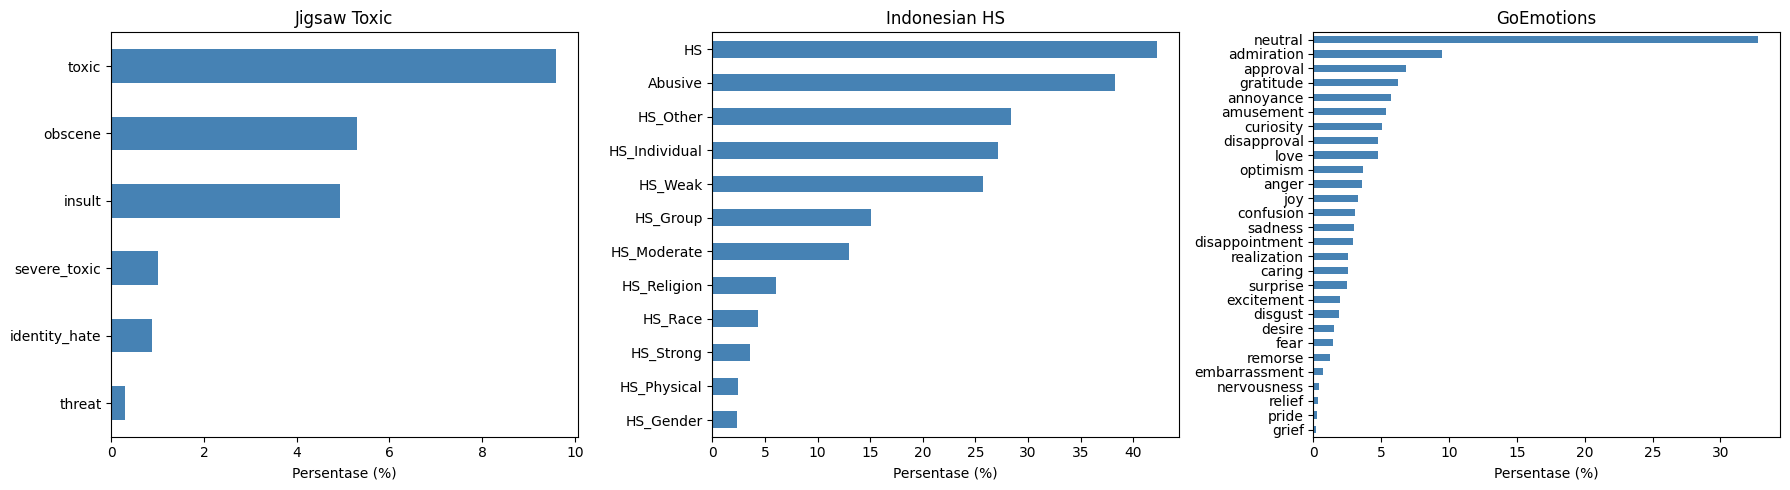

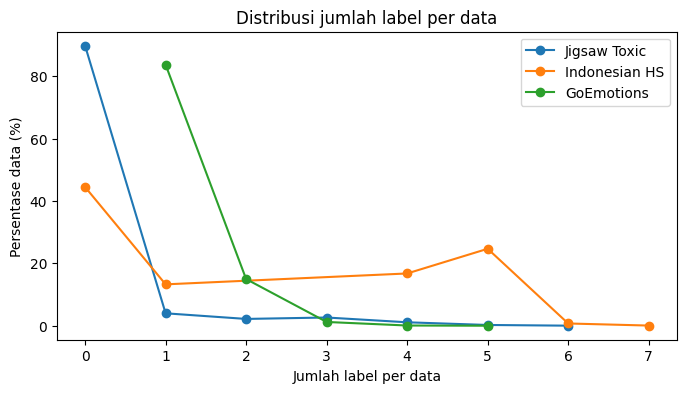

In [6]:
ml = pd.DataFrame([rin_jig, rin_id, rin_go]).set_index("Dataset")
ml["Valid Multilabel?"] = ml["% Data >1 Label (Multilabel)"] > 0
display(ml.T)

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, (t, n) in zip(ax, [(tab_jig, "Jigsaw Toxic"), (tab_id, "Indonesian HS"), (tab_go, "GoEmotions")]):
    plot_bar(a, t.sort_values("Persentase (%)"), n, horizontal=True)
plt.tight_layout(); plt.show()

fig, a = plt.subplots(figsize=(8, 4))
for n, Y in [("Jigsaw Toxic", df_jig[lab_jig].values), ("Indonesian HS", df_id[lab_id].values), ("GoEmotions", Y_go)]:
    d = pd.Series(np.asarray(Y).sum(axis=1)).value_counts(normalize=True).sort_index() * 100
    a.plot(d.index, d.values, marker="o", label=n)
a.set_xlabel("Jumlah label per data"); a.set_ylabel("Persentase data (%)")
a.set_title("Distribusi jumlah label per data"); a.legend(); plt.show()

In [7]:
col = "% Data >1 Label (Multilabel)"
print("Dataset valid sebagai multilabel (ada data berlabel >1):", ", ".join(ml[ml["Valid Multilabel?"]].index))
print(f"Paling multilabel : {ml[col].idxmax()} ({ml[col].max()}% data berlabel >1)")
print(f"Paling mendekati single-label : {ml[col].idxmin()} ({ml[col].min()}% data berlabel >1)")
print("\nCatatan: label HS_Weak/Moderate/Strong pada dataset Indonesia bersifat hierarkis terhadap label HS,")
print("sehingga persentase multilabelnya cenderung tinggi.")

Dataset valid sebagai multilabel (ada data berlabel >1): Jigsaw Toxic, Indonesian HS, GoEmotions
Paling multilabel : Indonesian HS (42.23% data berlabel >1)
Paling mendekati single-label : Jigsaw Toxic (6.18% data berlabel >1)

Catatan: label HS_Weak/Moderate/Strong pada dataset Indonesia bersifat hierarkis terhadap label HS,
sehingga persentase multilabelnya cenderung tinggi.


## Kesimpulan
(Isi setelah melihat output: bandingkan label cardinality, label density, dan persentase data berlabel >1 untuk menentukan dataset yang paling kuat sifat multilabel-nya.)

## Daftar Pustaka
- Jigsaw/Conversation AI. (2017). *Toxic Comment Classification Challenge*. Kaggle. https://www.kaggle.com/c/jigsaw-toxic-comment-classification-challenge
- Ibrohim, M. O., & Budi, I. (2019). Multi-label hate speech and abusive language detection in Indonesian Twitter. *Proceedings of the Third Workshop on Abusive Language Online*, 46-57. https://aclanthology.org/W19-3506/
- Demszky, D., Movshovitz-Attias, D., Ko, J., Cowen, A., Nemade, G., & Ravi, S. (2020). GoEmotions: A dataset of fine-grained emotions. *Proceedings of ACL 2020*. https://arxiv.org/abs/2005.00547

*(Tambahkan tanggal akses dan sesuaikan format sitasi dengan ketentuan dosen.)*